In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, mean_absolute_error,
    mean_squared_error, roc_auc_score
)
from sklearn.model_selection import (
    GridSearchCV, KFold, StratifiedKFold,
    cross_val_score, train_test_split
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"
MODELS = PROJECT_ROOT / "models"

print("Python:", sys.executable)
print("Notebook folder:", Path.cwd())

required_files = [
    "breast_cancer_dataset.csv",
    "titanic_dataset.csv",
    "ames_housing_dataset.csv",
    "red_wine_quality_dataset.csv"
]

for filename in required_files:
    print(filename, "→", (DATA / filename).is_file())

if all((DATA / filename).is_file() for filename in required_files):
    MODELS.mkdir(exist_ok=True)
    print("\nLab 3 setup ready!")

Python: C:\Users\Hp\anaconda3\envs\ml\python.exe
Notebook folder: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\all_experiments
breast_cancer_dataset.csv → True
titanic_dataset.csv → True
ames_housing_dataset.csv → True
red_wine_quality_dataset.csv → True

Lab 3 setup ready!


k= 1 cross-validated ROC AUC = 0.946
k= 3 cross-validated ROC AUC = 0.984
k= 5 cross-validated ROC AUC = 0.985
k= 7 cross-validated ROC AUC = 0.987
k=11 cross-validated ROC AUC = 0.988
k=21 cross-validated ROC AUC = 0.988

Selected k: 11


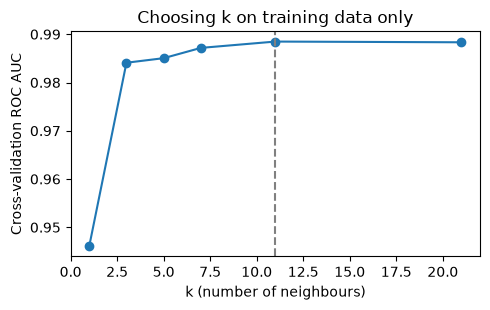

In [2]:
# Part A: KNN versus Gaussian naive Bayes
cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")

X_c = cancer.drop(
    columns=["id", "diagnosis", "Unnamed: 32"],
    errors="ignore"
)
y_c = (cancer["diagnosis"] == "M").astype(int)

Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(
    X_c, y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c
)

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

k_values = [1, 3, 5, 7, 11, 21]
cv_scores = {}

for k in k_values:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=k,
            weights="distance"
        ))
    ])

    scores = cross_val_score(
        candidate,
        Xc_train,
        yc_train,
        cv=cv,
        scoring="roc_auc"
    )

    cv_scores[k] = scores.mean()
    print(f"k={k:2d} cross-validated ROC AUC = {scores.mean():.3f}")

best_k = max(cv_scores, key=cv_scores.get)
print("\nSelected k:", best_k)

plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Cross-validation ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.show()

In [3]:
models = {
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(
            n_neighbors=best_k,
            weights="distance"
        ))
    ]),
    "GaussianNB": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB())
    ])
}

for name, model in models.items():
    model.fit(Xc_train, yc_train)

    pred = model.predict(Xc_valid)
    prob_c = model.predict_proba(Xc_valid)[:, 1]

    print(
        f"{name:10s} "
        f"accuracy={accuracy_score(yc_valid, pred):.3f} "
        f"roc_auc={roc_auc_score(yc_valid, prob_c):.3f}"
    )

KNN        accuracy=0.958 roc_auc=0.986
GaussianNB accuracy=0.944 roc_auc=0.992


two = ["radius_mean", "texture_mean"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

for ax, (name, estimator) in zip(axes, [
    ("Logistic regression", LogisticRegression(max_iter=2000)),
    (f"KNN (k={best_k})", KNeighborsClassifier(
        n_neighbors=best_k, weights="distance"
    )),
    ("Gaussian naive Bayes", GaussianNB())
]):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator)
    ])

    small.fit(Xc_train[two], yc_train)

    DecisionBoundaryDisplay.from_estimator(
        small,
        Xc_valid[two],
        ax=ax,
        alpha=0.3,
        response_method="predict",
        cmap="coolwarm"
    )

    ax.scatter(
        Xc_valid[two[0]],
        Xc_valid[two[1]],
        c=yc_valid,
        cmap="coolwarm",
        s=12,
        edgecolor="k",
        linewidth=0.3
    )

    accuracy = accuracy_score(
        yc_valid, small.predict(Xc_valid[two])
    )
    ax.set_title(f"{name}: {accuracy:.2f} accuracy")
    ax.set_xlabel("radius_mean")
    ax.set_ylabel("texture_mean")

plt.tight_layout()
plt.show()

### Part A — Observations

Five-fold cross-validation on the training partition selected k = 11,
with mean ROC AUC approximately 0.988.

Using all features, KNN achieved validation accuracy 0.958 and
ROC AUC 0.986. Gaussian naive Bayes achieved accuracy 0.944 and
ROC AUC 0.992. KNN had higher classification accuracy, while
Gaussian naive Bayes ranked the classes better by ROC AUC.

Using only radius_mean and texture_mean, the displayed accuracies
were approximately 0.88 for logistic regression, 0.90 for KNN,
and 0.86 for Gaussian naive Bayes. Logistic regression produced
a linear boundary, KNN followed local neighbourhoods, and
Gaussian naive Bayes produced a curved boundary.

In [6]:
titanic = pd.read_csv(DATA / "titanic_dataset.csv")

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
t_num = ["Age", "SibSp", "Parch", "Fare"]
t_cat = ["Pclass", "Sex", "Embarked"]

X_t = titanic[features]
y_t = titanic["Survived"]

tree_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), t_num),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), t_cat)
])

Xt_train, Xt_valid, yt_train, yt_valid = train_test_split(
    X_t, y_t,
    test_size=0.25,
    random_state=42,
    stratify=y_t
)

tree = Pipeline([
    ("preprocess", tree_preprocess),
    ("tree", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=12,
        random_state=42
    ))
])

tree.fit(Xt_train, yt_train)

print("Training accuracy:",
      round(accuracy_score(yt_train, tree.predict(Xt_train)), 3))
print("Validation accuracy:",
      round(accuracy_score(yt_valid, tree.predict(Xt_valid)), 3))

Training accuracy: 0.843
Validation accuracy: 0.767


|--- cat__Sex_female <= 0.50
|   |--- num__Age <= 3.50
|   |   |--- class: 1
|   |--- num__Age >  3.50
|   |   |--- cat__Pclass_1 <= 0.50
|   |   |   |--- num__Fare <= 48.09
|   |   |   |   |--- class: 0
|   |   |   |--- num__Fare >  48.09
|   |   |   |   |--- class: 0
|   |   |--- cat__Pclass_1 >  0.50
|   |   |   |--- num__Age <= 53.00
|   |   |   |   |--- class: 0
|   |   |   |--- num__Age >  53.00
|   |   |   |   |--- class: 0
|--- cat__Sex_female >  0.50
|   |--- cat__Pclass_3 <= 0.50
|   |   |--- num__Fare <= 28.86
|   |   |   |--- num__Age <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- num__Age >  37.00
|   |   |   |   |--- class: 1
|   |   |--- num__Fare >  28.86
|   |   |   |--- num__Parch <= 1.50
|   |   |   |   |--- class: 1
|   |   |   |--- num__Parch >  1.50
|   |   |   |   |--- class: 1
|   |--- cat__Pclass_3 >  0.50
|   |   |--- num__Fare <= 7.89
|   |   |   |--- cat__Embarked_S <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- cat__Embarked_S >  0.50
|   |

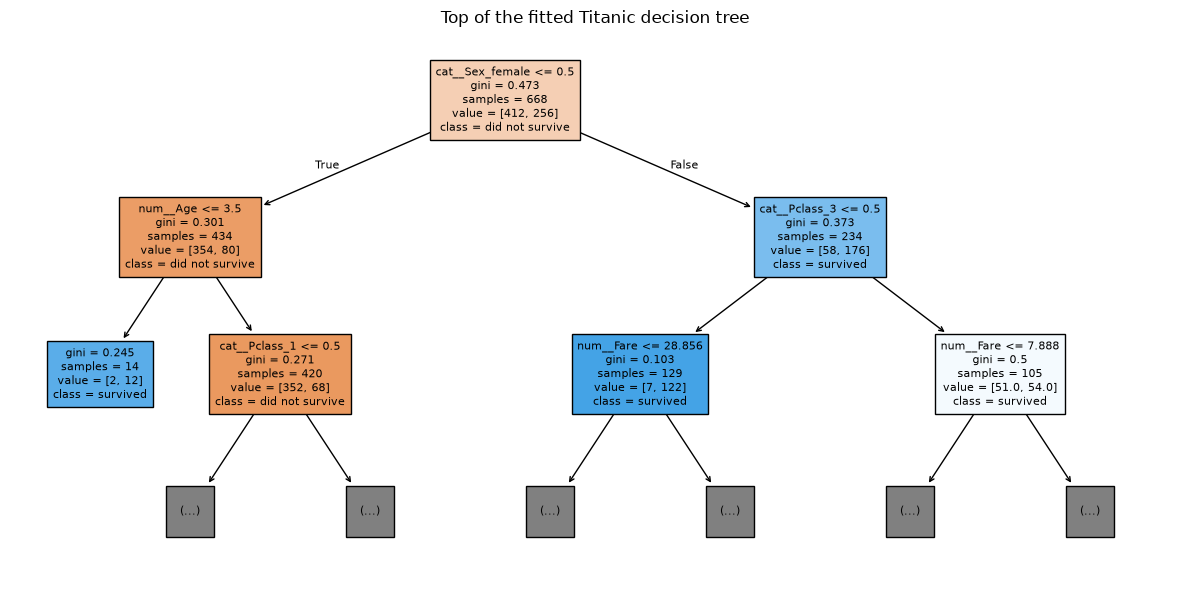

In [7]:
feature_names = list(
    tree.named_steps["preprocess"].get_feature_names_out()
)

print(export_text(
    tree.named_steps["tree"],
    feature_names=feature_names,
    max_depth=3
))

plt.figure(figsize=(12, 6))

plot_tree(
    tree.named_steps["tree"],
    feature_names=feature_names,
    class_names=["did not survive", "survived"],
    max_depth=2,
    filled=True,
    fontsize=8
)

plt.title("Top of the fitted Titanic decision tree")
plt.tight_layout()
plt.show()

,Depth,Training accuracy,Validation accuracy
0,1,0.793,0.767
1,2,0.808,0.758
2,3,0.832,0.785
3,4,0.852,0.776
4,5,0.868,0.767
5,6,0.882,0.771
6,7,0.892,0.767
7,8,0.913,0.740
8,9,0.927,0.749
9,10,0.939,0.740


Best depth by validation accuracy: 3


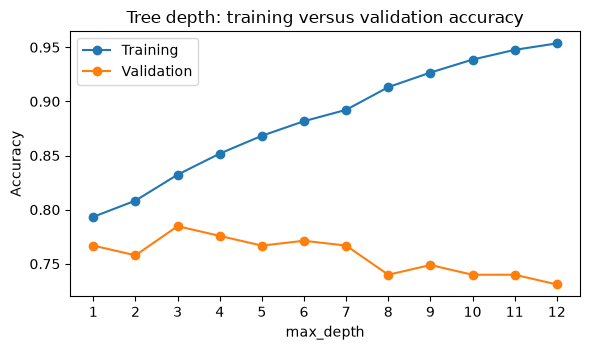

In [8]:
from sklearn.base import clone

depths = list(range(1, 13))
train_acc, valid_acc = [], []

for depth in depths:
    candidate_tree = Pipeline([
        ("preprocess", clone(tree_preprocess)),
        ("tree", DecisionTreeClassifier(
            max_depth=depth,
            random_state=42
        ))
    ])

    candidate_tree.fit(Xt_train, yt_train)

    train_acc.append(
        accuracy_score(yt_train, candidate_tree.predict(Xt_train))
    )
    valid_acc.append(
        accuracy_score(yt_valid, candidate_tree.predict(Xt_valid))
    )

depth_results = pd.DataFrame({
    "Depth": depths,
    "Training accuracy": train_acc,
    "Validation accuracy": valid_acc
})

display(depth_results.round(3))

best_depth = depths[int(np.argmax(valid_acc))]
print("Best depth by validation accuracy:", best_depth)

plt.figure(figsize=(6, 3.6))
plt.plot(depths, train_acc, marker="o", label="Training")
plt.plot(depths, valid_acc, marker="o", label="Validation")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Tree depth: training versus validation accuracy")
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
unrestricted_tree = Pipeline([
    ("preprocess", clone(tree_preprocess)),
    ("tree", DecisionTreeClassifier(
        max_depth=None,
        min_samples_leaf=1,
        random_state=42
    ))
])

unrestricted_tree.fit(Xt_train, yt_train)

for name, model in [
    ("Depth 4, minimum leaf 12", tree),
    ("Unrestricted, minimum leaf 1", unrestricted_tree)
]:
    print(name)
    print("Training accuracy:",
          round(accuracy_score(yt_train, model.predict(Xt_train)), 3))
    print("Validation accuracy:",
          round(accuracy_score(yt_valid, model.predict(Xt_valid)), 3))
    print()

Depth 4, minimum leaf 12
Training accuracy: 0.843
Validation accuracy: 0.767

Unrestricted, minimum leaf 1
Training accuracy: 0.978
Validation accuracy: 0.722



Removing the depth and minimum-leaf restrictions increased training accuracy from 0.843 to 0.978, while validation accuracy decreased from 0.767 to 0.722. The larger gap indicates overfitting. Both restrictions changed in this comparison; the earlier depth sweep isolated the effect of depth and achieved its highest validation accuracy at depth 3.

In [10]:
ames = pd.read_csv(DATA / "ames_housing_dataset.csv")

X_a = ames.drop(columns=["SalePrice", "Order", "PID"], errors="ignore")
y_a = np.log1p(ames["SalePrice"])

ames_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"),
     X_a.select_dtypes(include="number").columns),

    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), X_a.select_dtypes(exclude="number").columns)
])

ensembles = {
    "random_forest": RandomForestRegressor(
        n_estimators=150,
        max_features=0.8,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42
    )
}

cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}

for name, estimator in ensembles.items():
    pipe = Pipeline([
        ("preprocess", clone(ames_preprocess)),
        ("model", estimator)
    ])

    neg_mse = cross_val_score(
        pipe, X_a, y_a,
        cv=cv3,
        scoring="neg_mean_squared_error"
    )

    cv_rmse[name] = np.sqrt(-neg_mse)

    print(
        f"{name:18s} CV log-RMSE = "
        f"{cv_rmse[name].mean():.4f} "
        f"+/- {cv_rmse[name].std():.4f}"
    )

random_forest      CV log-RMSE = 0.1382 +/- 0.0118
gradient_boosting  CV log-RMSE = 0.1273 +/- 0.0141


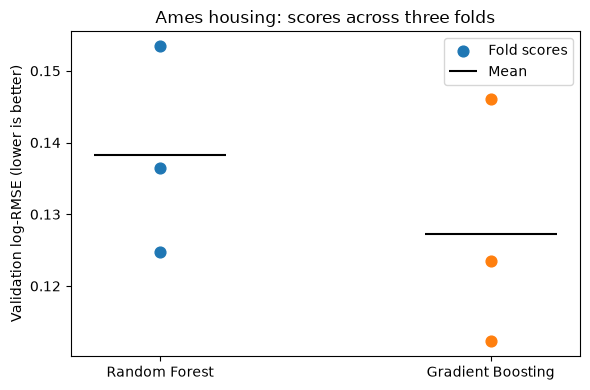

In [11]:
plt.figure(figsize=(6, 4))

for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter(
        [i] * len(values), values,
        s=60,
        label="Fold scores" if i == 0 else None
    )
    plt.hlines(
        values.mean(), i - 0.2, i + 0.2,
        color="black",
        label="Mean" if i == 0 else None
    )

plt.xticks(range(len(cv_rmse)), ["Random Forest", "Gradient Boosting"])
plt.ylabel("Validation log-RMSE (lower is better)")
plt.title("Ames housing: scores across three folds")
plt.legend()
plt.tight_layout()
plt.show()

Gradient Boosting achieved a lower mean cross-validation log-RMSE (0.1273) than Random Forest (0.1382), an improvement of approximately 7.9%. However, Gradient Boosting showed slightly greater variation across folds (0.0141 versus 0.0118). These three-fold results favour Gradient Boosting on average but do not establish a statistically significant difference. Errors are measured on log-transformed sale prices, not directly in dollars

In [12]:
wine = pd.read_csv(DATA / "red_wine_quality_dataset.csv")

X_w = wine.drop(columns="quality")
y_w = wine["quality"]

Xw_train, Xw_valid, yw_train, yw_valid = train_test_split(
    X_w, y_w,
    test_size=0.25,
    random_state=42
)

wine_models = {
    "random_forest": RandomForestRegressor(
        n_estimators=400,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "gradient_boosting": GradientBoostingRegressor(
        random_state=42
    )
}

wine_pred = {}

for name, model in wine_models.items():
    model.fit(Xw_train, yw_train)
    wine_pred[name] = model.predict(Xw_valid)

    mae = mean_absolute_error(yw_valid, wine_pred[name])
    rmse = np.sqrt(mean_squared_error(yw_valid, wine_pred[name]))

    print(f"{name:18s} MAE = {mae:.3f}, RMSE = {rmse:.3f}")

random_forest      MAE = 0.432, RMSE = 0.565
gradient_boosting  MAE = 0.476, RMSE = 0.597


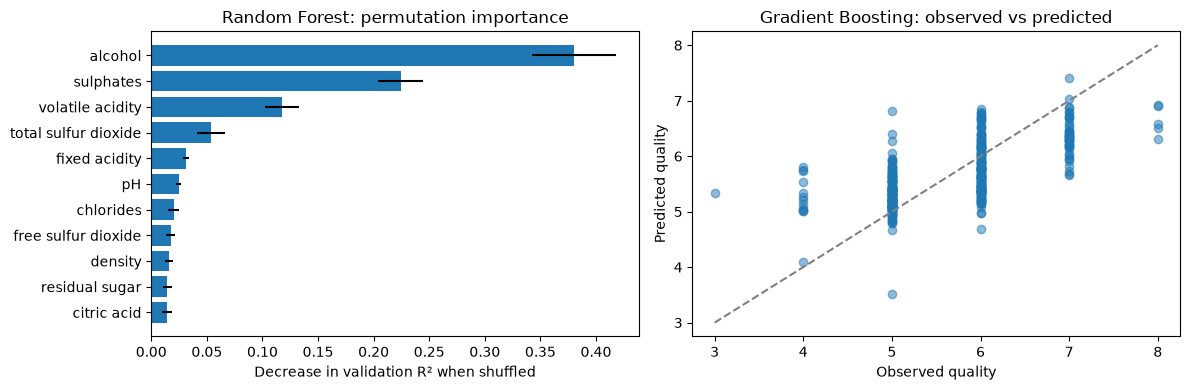

In [13]:
importance = permutation_importance(
    wine_models["random_forest"],
    Xw_valid,
    yw_valid,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

order = np.argsort(importance.importances_mean)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].barh(
    X_w.columns[order],
    importance.importances_mean[order],
    xerr=importance.importances_std[order]
)
axes[0].set_xlabel("Decrease in validation R² when shuffled")
axes[0].set_title("Random Forest: permutation importance")

axes[1].scatter(
    yw_valid,
    wine_pred["gradient_boosting"],
    alpha=0.5
)

low = yw_valid.min()
high = yw_valid.max()
axes[1].plot(
    [low, high], [low, high],
    linestyle="--",
    color="grey"
)
axes[1].set_xlabel("Observed quality")
axes[1].set_ylabel("Predicted quality")
axes[1].set_title("Gradient Boosting: observed vs predicted")

plt.tight_layout()
plt.show()

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c,
    test_size=0.25,
    random_state=42,
    stratify=y_c
)

svm_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", SVC())
])

# Gamma only affects the RBF kernel, so tune it there.
param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10, 100]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1]
    }
]

search = GridSearchCV(
    svm_pipe,
    param_grid=param_grid,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="roc_auc",
    n_jobs=-1
)

search.fit(X_train, y_train)

score = search.decision_function(X_test)
pred = search.predict(X_test)

print("Best parameters:", search.best_params_)
print("Best CV ROC AUC:", round(search.best_score_, 3))
print("Validation accuracy:", round(accuracy_score(y_test, pred), 3))
print("Validation ROC AUC:", round(roc_auc_score(y_test, score), 3))

Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
Best CV ROC AUC: 0.995
Validation accuracy: 0.979
Validation ROC AUC: 0.997


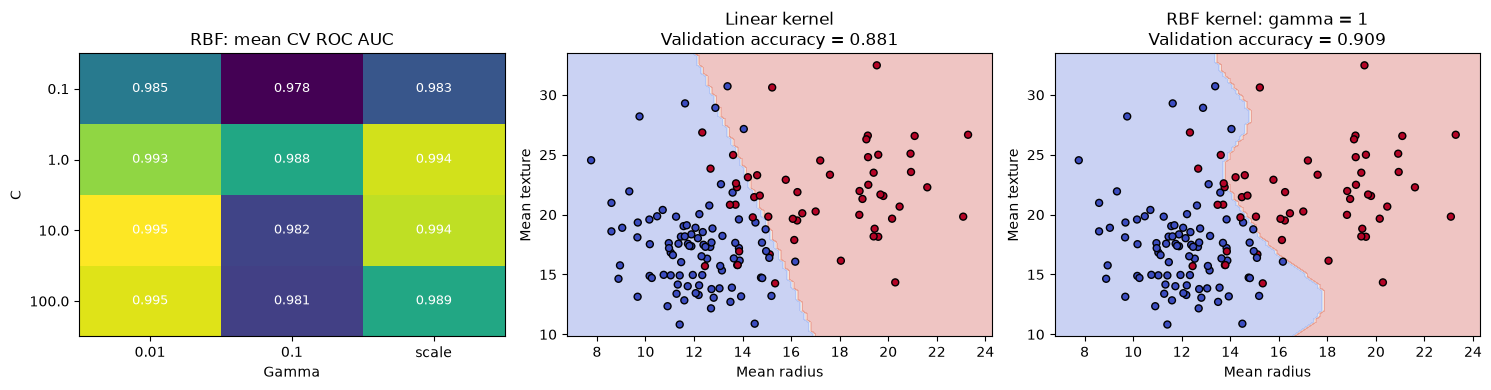

In [15]:
results = pd.DataFrame(search.cv_results_)

rbf = results[
    results["param_model__kernel"] == "rbf"
].copy()

rbf["gamma"] = rbf["param_model__gamma"].astype(str)

grid = rbf.pivot(
    index="param_model__C",
    columns="gamma",
    values="mean_test_score"
).sort_index()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

heatmap = axes[0].imshow(
    grid.to_numpy(dtype=float),
    aspect="auto",
    cmap="viridis"
)

axes[0].set_xticks(range(len(grid.columns)))
axes[0].set_xticklabels(grid.columns)
axes[0].set_yticks(range(len(grid.index)))
axes[0].set_yticklabels(grid.index)
axes[0].set_xlabel("Gamma")
axes[0].set_ylabel("C")
axes[0].set_title("RBF: mean CV ROC AUC")

for row in range(len(grid.index)):
    for col in range(len(grid.columns)):
        axes[0].text(
            col, row,
            f"{grid.iloc[row, col]:.3f}",
            ha="center", va="center",
            color="white", fontsize=9
        )

two = ["radius_mean", "texture_mean"]

examples = [
    ("Linear kernel", SVC(kernel="linear", C=1)),
    ("RBF kernel: gamma = 1", SVC(kernel="rbf", C=1, gamma=1))
]

for ax, (title, estimator) in zip(axes[1:], examples):
    small = Pipeline([
        ("scale", StandardScaler()),
        ("model", estimator)
    ])

    small.fit(X_train[two], y_train)

    DecisionBoundaryDisplay.from_estimator(
        small,
        X_test[two],
        response_method="predict",
        cmap="coolwarm",
        alpha=0.3,
        ax=ax
    )

    ax.scatter(
        X_test[two[0]], X_test[two[1]],
        c=y_test, cmap="coolwarm",
        edgecolors="k", s=25
    )

    accuracy = accuracy_score(
        y_test, small.predict(X_test[two])
    )

    ax.set_title(f"{title}\nValidation accuracy = {accuracy:.3f}")
    ax.set_xlabel("Mean radius")
    ax.set_ylabel("Mean texture")

plt.tight_layout()
plt.show()

In [16]:
model_path = MODELS / "breast_cancer_svm.joblib"

joblib.dump(search.best_estimator_, model_path)

loaded = joblib.load(model_path)
loaded_pred = loaded.predict(X_test)

print("Saved model:", model_path)
print("File size:", round(model_path.stat().st_size / 1024, 1), "KB")
print("Reloaded predictions match:", np.array_equal(pred, loaded_pred)

SyntaxError: incomplete input (2540107403.py, line 10)

In [17]:
model_path = MODELS / "breast_cancer_svm.joblib"

joblib.dump(search.best_estimator_, model_path)

loaded = joblib.load(model_path)
loaded_pred = loaded.predict(X_test)

print("Saved model:", model_path)
print("File size:", round(model_path.stat().st_size / 1024, 1), "KB")
print("Reloaded predictions match:", np.array_equal(pred, loaded_pred))

Saved model: C:\Users\Hp\Documents\UTP-MACHINE-LEARNING\models\breast_cancer_svm.joblib
File size: 16.5 KB
Reloaded predictions match: True


In [18]:
linear_search = GridSearchCV(
    Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="linear"))
    ]),
    param_grid={"model__C": [0.1, 1, 10, 100]},
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    scoring="roc_auc",
    n_jobs=-1
)

linear_search.fit(X_train, y_train)

linear_auc = roc_auc_score(
    y_test,
    linear_search.decision_function(X_test)
)

# The earlier search selected an RBF model.
rbf_auc = roc_auc_score(
    y_test,
    search.decision_function(X_test)
)

print("Best linear C:", linear_search.best_params_["model__C"])
print("Linear CV ROC AUC:", round(linear_search.best_score_, 4))
print("Linear validation ROC AUC:", round(linear_auc, 4))
print("RBF validation ROC AUC:", round(rbf_auc, 4))
print("RBF minus linear AUC:", round(rbf_auc - linear_auc, 4))

Best linear C: 0.1
Linear CV ROC AUC: 0.9932
Linear validation ROC AUC: 0.9971
RBF validation ROC AUC: 0.9969
RBF minus linear AUC: -0.0002


The best linear SVM used C = 0.1 and achieved cross-validation ROC AUC of 0.9932. Its validation ROC AUC was 0.9971, compared with 0.9969 for the tuned RBF SVM. The difference of 0.0002 is negligible on this split and does not establish that either kernel is generally superior. The linear model is competitive despite its simpler boundary. The saved RBF model was selected using cross-validation rather than the validation comparison.

## Understanding questions

### 1. What is the geometric meaning of a larger separating margin in an SVM?

A larger margin means a wider gap between the separating hyperplane and the margin boundaries defined by the support vectors. This provides greater separation between classes in feature space and can improve generalisation. A soft-margin SVM balances a wide margin against allowing some points inside the margin or on the wrong side of the boundary.

### 2. How do C and RBF gamma change the flexibility of the decision boundary?

C controls the penalty for margin violations. A smaller C applies stronger regularisation, allowing more violations to favour a wider margin. A larger C penalises violations more strongly and can fit the training data more closely. For the RBF kernel, a small gamma gives each training point a broad influence, usually producing smoother boundaries. A large gamma makes the influence more local, allowing more complex boundaries that may overfit. C and gamma should therefore be tuned together.

### 3. Why must scaling and SVM hyperparameter selection happen inside the validation procedure?

SVMs depend on distances and dot products, so features with large numerical scales can dominate the model. Scaling parameters must be learned from each training fold and then applied to its validation fold. Scaling before cross-validation would leak information from the validation folds. A pipeline inside GridSearchCV keeps scaling and model fitting within each fold, while cross-validation selects hyperparameters using only the training data. An untouched test set should be reserved for the final evaluation.